# Bounded MOIA and FlipFlop Klagenfurt Spatial Comparison

This notebook is the whole-Klagenfurt counterpart to `flipflop_vs_moia_bounded_comparison.ipynb`. Instead of the Neubau-scoped FlipFlop sample, it draws from the full regional model (`full_draws/draws_Baseline.csv`, 471,140 calibrated trips) and shows the new results produced by `prepare_klagenfurt_baseline_draw1.py`: the trips retained after the same MOIA-frame and network-coverage filtering, and the final 100-request pilot demand actually written for the FleetPy simulation.

**Important:** FlipFlop trips outside the MOIA box are excluded from the visualizations below. Retained rows are further reduced to those covered by the `flipflop_neubau_extended` network, and the pilot cap keeps only the first 100 by departure time.

## Why A Bounded View?

The available FleetPy street geometry covers the extended Klagenfurt operating area. The full-region FlipFlop model extends across all 27 calibrated Gemeinden, well beyond that area. Plotting every point leaves the comparison dominated by trips far outside Klagenfurt.

This notebook therefore uses the MOIA dataset's coordinate bounding box as a transparent comparison box, exactly as the Neubau notebook does. A FlipFlop trip is retained only when both its origin and destination are inside that box.

In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

ROOT_DIR = Path.cwd().resolve()
while ROOT_DIR.name != 'FleetPy' and ROOT_DIR.parent != ROOT_DIR:
    ROOT_DIR = ROOT_DIR.parent

MOIA_FILE = ROOT_DIR / 'data' / 'demand' / 'trips_klagenfurt.csv'
FLIPFLOP_FILE = ROOT_DIR / 'data' / 'SampleFiles_recovered' / 'SampleFiles' / 'full_draws' / 'draws_Baseline.csv'
RETAINED_DEMAND_FILE = ROOT_DIR / 'data' / 'demand' / 'flipflop_klagenfurt_pilot' / 'matched' / 'flipflop_neubau_extended' / 'draw1_0700_0900_all_modes.csv'
NETWORK_FILE = ROOT_DIR / 'klagenfurt_network_extended.gpkg'
NETWORK_NODES_FILE = ROOT_DIR / 'data' / 'networks' / 'flipflop_neubau_extended' / 'base' / 'nodes.csv'
OUTPUT_DIR = ROOT_DIR / 'studies' / 'flipflop_drt_integration_pilot' / 'results'

moia = pd.read_csv(MOIA_FILE)
flipflop_all = pd.read_csv(FLIPFLOP_FILE, usecols=['draw', 'trip_id', 'drawn_mode', 'starting_time', 'lat_start', 'lon_start', 'lat_end', 'lon_end'], parse_dates=['starting_time'])
flipflop_all = flipflop_all[(flipflop_all['draw'] == 1) & (flipflop_all['starting_time'].dt.hour.isin([7, 8]))].copy()
retained_demand = pd.read_csv(RETAINED_DEMAND_FILE)
network = gpd.read_file(NETWORK_FILE).to_crs(epsg=3857)
nodes = pd.read_csv(NETWORK_NODES_FILE)
print(f'MOIA trips: {len(moia):,}')
print(f'FlipFlop Draw 1, 07:00-09:00 trips before cutoff: {len(flipflop_all):,}')
print(f'Retained pilot demand (matched to network, capped): {len(retained_demand):,}')
print(f'Network street segments: {len(network):,}')

MOIA trips: 1,067
FlipFlop Draw 1, 07:00-09:00 trips before cutoff: 63,774
Retained pilot demand (matched to network, capped): 100
Network street segments: 8,277


## Define The Study Box

The box is derived from the observed MOIA coordinates rather than chosen visually. It contains all MOIA origins and destinations, and it provides the common spatial frame for both datasets, identical to the Neubau notebook's box.

In [2]:
all_moia_x = pd.concat([moia['origin_x'], moia['destination_x']])
all_moia_y = pd.concat([moia['origin_y'], moia['destination_y']])
box = {
    'min_lon': all_moia_x.min(),
    'max_lon': all_moia_x.max(),
    'min_lat': all_moia_y.min(),
    'max_lat': all_moia_y.max(),
}
print('MOIA comparison box:')
for key, value in box.items():
    print(f'  {key}: {value:.6f}')

MOIA comparison box:
  min_lon: 14.218684
  max_lon: 14.413207
  min_lat: 46.579880
  max_lat: 46.700038


In [3]:
flipflop_in_box = flipflop_all[
    flipflop_all['lon_start'].between(box['min_lon'], box['max_lon'])
    & flipflop_all['lat_start'].between(box['min_lat'], box['max_lat'])
    & flipflop_all['lon_end'].between(box['min_lon'], box['max_lon'])
    & flipflop_all['lat_end'].between(box['min_lat'], box['max_lat'])
].copy()
cutoff_count = len(flipflop_all) - len(flipflop_in_box)
retained_share = len(flipflop_in_box) / len(flipflop_all)
print(f'FlipFlop trips retained inside box: {len(flipflop_in_box):,} ({retained_share:.1%})')
print(f'FlipFlop trips cut off outside box: {cutoff_count:,} ({1 - retained_share:.1%})')
print('The cutoff is applied to complete trips: both endpoints must be inside the box.')
print('Retained FlipFlop modes:')
print(flipflop_in_box['drawn_mode'].value_counts().to_string())

from scipy.spatial import cKDTree

MAX_NEAREST_DISTANCE = 0.005
NETWORK_EDGES_FILE = ROOT_DIR / 'data' / 'networks' / 'flipflop_neubau_extended' / 'base' / 'edges.csv'
edges = pd.read_csv(NETWORK_EDGES_FILE)
routable_node_ids = pd.unique(edges[['from_node', 'to_node']].to_numpy().ravel())
routable_nodes = nodes[nodes['node_index'].isin(routable_node_ids)]
tree = cKDTree(routable_nodes[['pos_x', 'pos_y']].to_numpy())
start_dist, _ = tree.query(flipflop_in_box[['lon_start', 'lat_start']].to_numpy())
end_dist, _ = tree.query(flipflop_in_box[['lon_end', 'lat_end']].to_numpy())
NETWORK_COVERED_COUNT = int(((start_dist <= MAX_NEAREST_DISTANCE) & (end_dist <= MAX_NEAREST_DISTANCE)).sum())

print()
print(f'Of those {len(flipflop_in_box):,} in-box trips, {NETWORK_COVERED_COUNT:,} are also network-covered; the pilot demand file keeps the first {len(retained_demand):,} of those by departure time.')


FlipFlop trips retained inside box: 26,290 (41.2%)
FlipFlop trips cut off outside box: 37,484 (58.8%)
The cutoff is applied to complete trips: both endpoints must be inside the box.
Retained FlipFlop modes:
drawn_mode
Car     16433
Foot     4578
PT       2900
Bike     2379



Of those 26,290 in-box trips, 22,782 are also network-covered; the pilot demand file keeps the first 100 of those by departure time.


## Visualization 1: One Combined Map

This is the main comparison figure. Color identifies the dataset and marker shape identifies the endpoint type: circles are origins and X markers are destinations. Orange shows every in-box FlipFlop trip (before network-coverage filtering and the pilot cap); the smaller green markers highlight the 100 requests actually retained for the FleetPy simulation ('new results'). Only points inside the MOIA box are shown. The local GeoPackage street layer is included for geographic context.

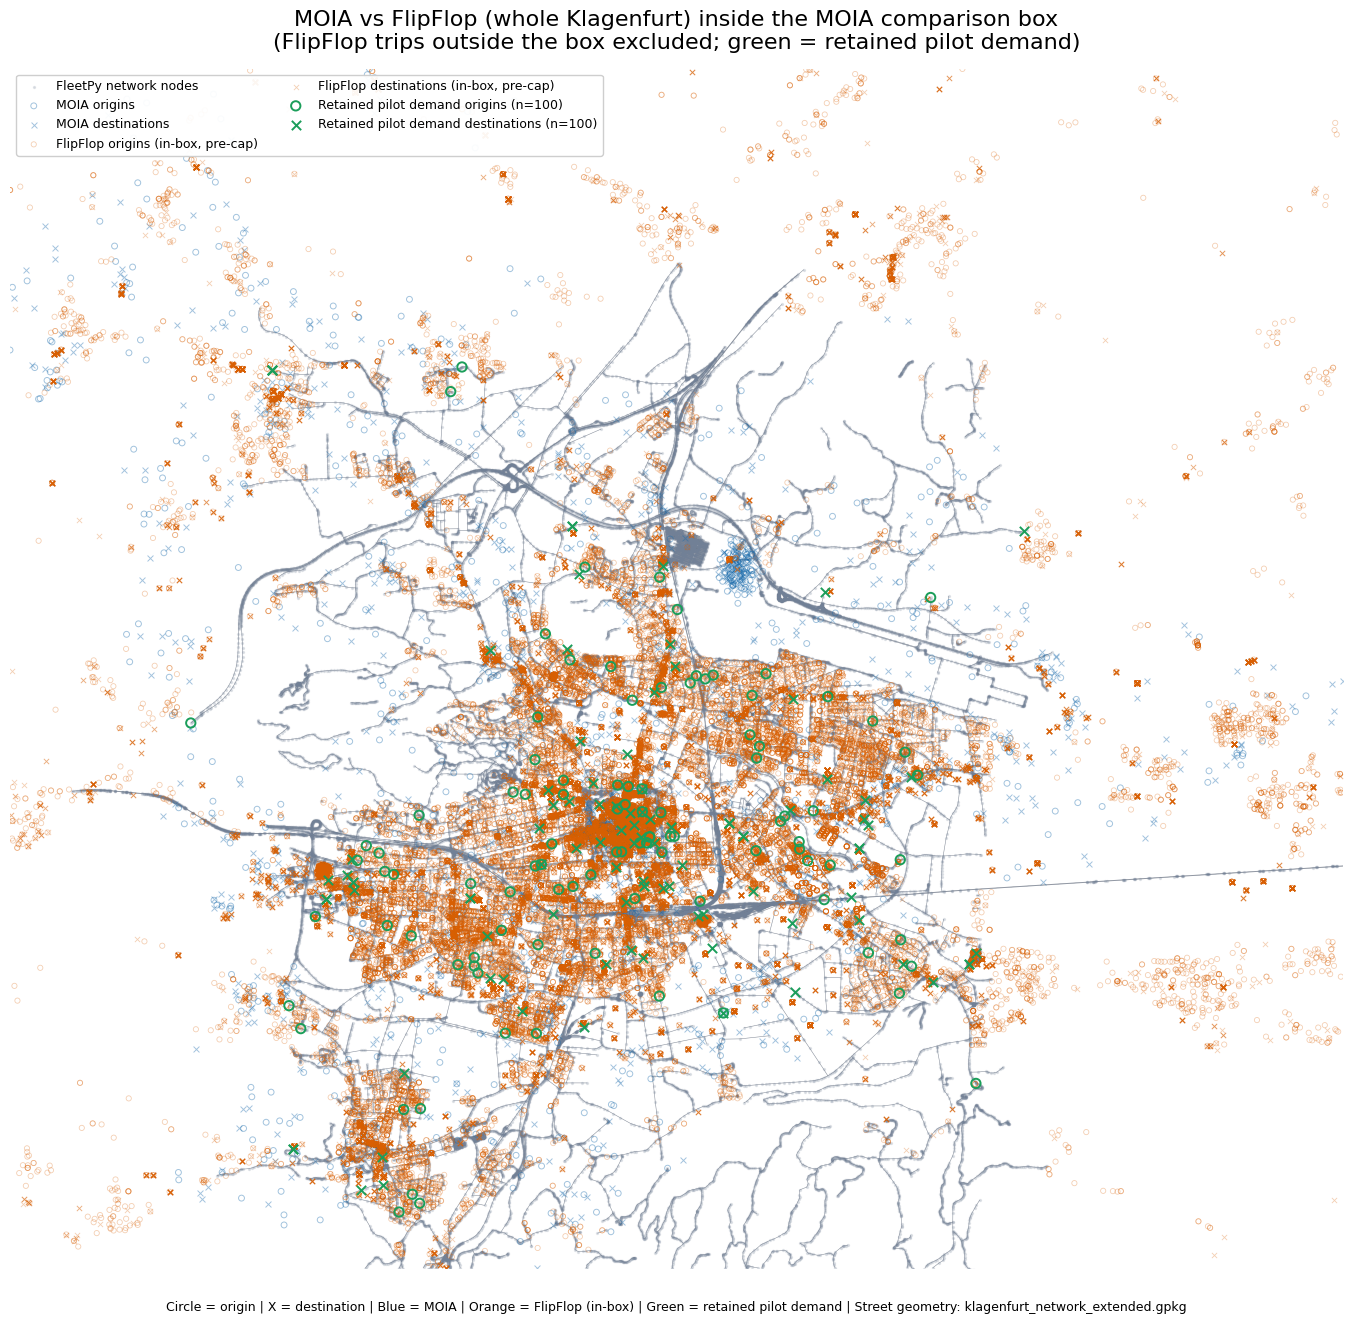

/Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/flipflop_drt_integration_pilot/results/flipflop_vs_moia_klagenfurt_bounded_combined_map.png


In [4]:
def web_points(x, y):
    return gpd.GeoSeries(gpd.points_from_xy(x, y), crs='EPSG:4326').to_crs(epsg=3857)

moia_origins = web_points(moia['origin_x'], moia['origin_y'])
moia_destinations = web_points(moia['destination_x'], moia['destination_y'])
flipflop_origins = web_points(flipflop_in_box['lon_start'], flipflop_in_box['lat_start'])
flipflop_destinations = web_points(flipflop_in_box['lon_end'], flipflop_in_box['lat_end'])
network_nodes = web_points(nodes['pos_x'], nodes['pos_y'])

retained_nodes = nodes.set_index('node_index')
retained_start = retained_nodes.loc[retained_demand['start']]
retained_end = retained_nodes.loc[retained_demand['end']]
retained_origins = web_points(retained_start['pos_x'], retained_start['pos_y'])
retained_destinations = web_points(retained_end['pos_x'], retained_end['pos_y'])

fig, ax = plt.subplots(figsize=(18, 14))
network.plot(ax=ax, linewidth=0.4, color='#4a5568', alpha=0.65, zorder=1)
ax.scatter(network_nodes.x, network_nodes.y, s=2, color='#718096', alpha=0.18, label='FleetPy network nodes', zorder=2)
ax.scatter(moia_origins.x, moia_origins.y, s=18, marker='o', facecolors='none', edgecolors='#1769aa', linewidths=0.7, alpha=0.4, label='MOIA origins', zorder=3)
ax.scatter(moia_destinations.x, moia_destinations.y, s=18, marker='x', color='#1769aa', linewidths=0.7, alpha=0.4, label='MOIA destinations', zorder=3)
ax.scatter(flipflop_origins.x, flipflop_origins.y, s=14, marker='o', facecolors='none', edgecolors='#d95f02', linewidths=0.6, alpha=0.3, label='FlipFlop origins (in-box, pre-cap)', zorder=4)
ax.scatter(flipflop_destinations.x, flipflop_destinations.y, s=14, marker='x', color='#d95f02', linewidths=0.6, alpha=0.3, label='FlipFlop destinations (in-box, pre-cap)', zorder=4)
ax.scatter(retained_origins.x, retained_origins.y, s=45, marker='o', facecolors='none', edgecolors='#1b9e5a', linewidths=1.4, label='Retained pilot demand origins (n=100)', zorder=5)
ax.scatter(retained_destinations.x, retained_destinations.y, s=45, marker='x', color='#1b9e5a', linewidths=1.4, label='Retained pilot demand destinations (n=100)', zorder=5)
ax.set_xlim(*web_points(pd.Series([box['min_lon'], box['max_lon']]), pd.Series([box['min_lat'], box['max_lat']])).total_bounds[[0, 2]])
ax.set_ylim(*web_points(pd.Series([box['min_lon'], box['max_lon']]), pd.Series([box['min_lat'], box['max_lat']])).total_bounds[[1, 3]])
ax.set_title('MOIA vs FlipFlop (whole Klagenfurt) inside the MOIA comparison box\n(FlipFlop trips outside the box excluded; green = retained pilot demand)', fontsize=16, pad=14)
ax.legend(loc='upper left', framealpha=0.95, ncol=2, fontsize=9)
ax.set_axis_off()
fig.text(0.5, 0.02, 'Circle = origin | X = destination | Blue = MOIA | Orange = FlipFlop (in-box) | Green = retained pilot demand | Street geometry: klagenfurt_network_extended.gpkg', ha='center', fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 0.96))
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
combined_output = OUTPUT_DIR / 'flipflop_vs_moia_klagenfurt_bounded_combined_map.png'
fig.savefig(combined_output, dpi=180, bbox_inches='tight')
plt.show()
print(combined_output)

## Interpretation And Limits

- The figures answer a spatial-comparison question inside the MOIA box, now for the full-region FlipFlop model rather than the Neubau-scoped one.
- Unlike the Neubau notebook, the in-box FlipFlop population here is large (tens of thousands of trips) because it is not pre-restricted to a small area; the green markers show the much smaller subset actually usable as FleetPy demand today.
- The gap between the orange (in-box) and green (retained) markers is the network-coverage filter plus the 100-request pilot cap from `prepare_klagenfurt_baseline_draw1.py` — most in-box trips are dropped only by the pilot cap, not by lack of network coverage.
- They do not describe the full geographic distribution of FlipFlop trips, and they do not replace the full FlipFlop mode-choice hypothesis test.
- For FleetPy operations, an additional routability filter is still required because a point can be inside the box but belong to a disconnected part of the street graph; `prepare_klagenfurt_baseline_draw1.py` already applies this via nearest-node distance thresholding.
- Any operational result should report both the retained request count and the excluded-trip count, as done above.